# Router and Skill Evaluation

In [1]:
import phoenix as px
import os
import json
from tqdm import tqdm #just a progress bar library to show the progress
from phoenix.evals import(
    TOOL_CALLING_PROMPT_TEMPLATE, #pre-written system templates
    llm_classify,
    OpenAIModel
)
from phoenix.trace import SpanEvaluations
from phoenix.trace.dsl import SpanQuery
from openinference.instrumentation import suppress_tracing

import nest_asyncio
nest_asyncio.apply() #to allow nested asynchronous executions

<b>llm_classify:</b> The execution function. It takes your agent's logs, combines them with the prompt template, sends them to the OpenAIModel, and returns a score (e.g., pass/fail).<br>
<b>SpanQuery:</b> A filtering tool. Your agent generates hundreds of spans (retrieval, routing, tool execution). SpanQuery allows you to fetch only the specific spans you want to evaluate (e.g., pulling only the LLM routing decisions) from the database.<br>
<b>SpanEvaluations:</b> The data container that packages the final grades from llm_classify so they can be injected directly into the Phoenix dashboard alongside the original traces.<br>
<b>suppress_tracing:</b> A critical context manager. When you use an LLM to grade your agent, you do not want the tracer to record the judge's LLM calls and mix them into your agent's telemetry. This temporarily mutes the flight recorder.<br>


In [2]:
PROJECT_NAME = "evaluating-agent"

In [3]:
from utils import run_agent, start_main_span, tools, get_phoenix_endpoint

🔭 OpenTelemetry Tracing Details 🔭
|  Phoenix Project: evaluating-agent
|  Span Processor: SimpleSpanProcessor
|  Collector Endpoint: https://s172-29-22-106p6006.lab-aws-production.deeplearning.ai/v1/traces
|  Transport: HTTP + protobuf
|  Transport Headers: {}
|  
|  Using a default SpanProcessor. `add_span_processor` will overwrite this default.
|  
|  `register` has set this TracerProvider as the global OpenTelemetry default.
|  To disable this behavior, call `register` with `set_global_tracer_provider=False`.



In [4]:
agent_questions = [
    "What was the most popular product SKU?",
    "What was the total revenue across all stores?",
    "Which store had the highest sales volume?",
    "Create a bar chart showing total sales by store",
    "What percentage of items were sold on promotion?",
    "What was the average transaction value?"
]

for question in tqdm(agent_questions, desc = "processing questions"): #tqdm takes iterable and desc means description
    try:
        result = start_main_span([{"role": "user", "content": question}])
    
    except Exception as e:
        print(f"coudn't process the question {question}")
        print(e)
        continue

processing questions:   0%|          | 0/6 [00:00<?, ?it/s]

Starting main span with messages: [{'role': 'user', 'content': 'What was the most popular product SKU?'}]
Running agent with messages: [{'role': 'user', 'content': 'What was the most popular product SKU?'}]
Starting router call span
Received response with tool calls: True
Starting tool calls span


processing questions:  17%|█▋        | 1/6 [00:00<00:04,  1.09it/s]

Starting router call span
Received response with tool calls: False
No tool calls, returning final response
Starting main span with messages: [{'role': 'user', 'content': 'What was the total revenue across all stores?'}]
Running agent with messages: [{'role': 'user', 'content': 'What was the total revenue across all stores?'}]
Starting router call span
Received response with tool calls: True
Starting tool calls span


processing questions:  33%|███▎      | 2/6 [00:01<00:02,  1.55it/s]

Starting router call span
Received response with tool calls: False
No tool calls, returning final response
Starting main span with messages: [{'role': 'user', 'content': 'Which store had the highest sales volume?'}]
Running agent with messages: [{'role': 'user', 'content': 'Which store had the highest sales volume?'}]
Starting router call span
Received response with tool calls: True
Starting tool calls span


... (4 outputs left out)

processing questions:  83%|████████▎ | 5/6 [00:03<00:00,  1.53it/s]

Starting router call span
Received response with tool calls: False
No tool calls, returning final response
Starting main span with messages: [{'role': 'user', 'content': 'What was the average transaction value?'}]
Running agent with messages: [{'role': 'user', 'content': 'What was the average transaction value?'}]
Starting router call span
Received response with tool calls: True
Starting tool calls span


processing questions: 100%|██████████| 6/6 [00:03<00:00,  1.58it/s]

Starting router call span
Received response with tool calls: False
No tool calls, returning final response


In [5]:
print(get_phoenix_endpoint())

https://s172-29-22-106p6006.lab-aws-production.deeplearning.ai/


## Evaluating router using LLM-as-a-judge

In [6]:
print(TOOL_CALLING_PROMPT_TEMPLATE)


You are an evaluation assistant evaluating questions and tool calls to
determine whether the tool called would answer the question. The tool
calls have been generated by a separate agent, and chosen from the list of
tools provided below. It is your job to decide whether that agent chose
the right tool to call.

    [BEGIN DATA]
    ************
    [Question]: {question}
    ************
    [Tool Called]: {tool_call}
    [END DATA]

Your response must be single word, either "correct" or "incorrect",
and should not contain any text or characters aside from that word.
"incorrect" means that the chosen tool would not answer the question,
the tool includes information that is not presented in the question,
or that the tool signature includes parameter values that don't match
the formats specified in the tool signatures below.

"correct" means the correct tool call was chosen, the correct parameters
were extracted from the question, the tool call generated is runnable and correct,
and tha

In [7]:
#lets get the data out of observability plateform i.e. phoenix
#we will get the tool calls made by the router
query = SpanQuery().where(
    "span_kind == 'LLM'"
).select(
    question = "input.value",
    tool_call = "llm.tools"
) #this is not enough to filter out the router since we are only selecting llm as span kind

tool_calls_df = px.Client().query_spans(
    query,
    project_name = PROJECT_NAME,
    timeout = None
)

/usr/local/lib/python3.11/site-packages/phoenix/utilities/client.py:45: UserWarning: ⚠️⚠️ The Phoenix server (12.31.2) and client (7.0.0) versions are severely mismatched. Upgrade  either the client or server to ensure API compatibility ⚠️⚠️
  warnings.warn(


In [8]:
tool_calls_df.head()

,question,tool_call
context.span_id,,
191a014cf24a1408,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...","[{'tool': {'json_schema': '{""type"": ""function""..."
22a05dba08bd7c1e,"{""messages"": [{""role"": ""user"", ""content"": ""\nG...",None
10a7936300ebd246,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...","[{'tool': {'json_schema': '{""type"": ""function""..."
8c8b8dd344938f1f,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...","[{'tool': {'json_schema': '{""type"": ""function""..."
2184e67129c97c8d,"{""messages"": [{""role"": ""user"", ""content"": ""\nG...",None


In [9]:
tool_calls_df = tool_calls_df.dropna(subset=["tool_call"])
tool_calls_df.head()

,question,tool_call
context.span_id,,
191a014cf24a1408,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...","[{'tool': {'json_schema': '{""type"": ""function""..."
10a7936300ebd246,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...","[{'tool': {'json_schema': '{""type"": ""function""..."
8c8b8dd344938f1f,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...","[{'tool': {'json_schema': '{""type"": ""function""..."
24076b87b52f274a,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...","[{'tool': {'json_schema': '{""type"": ""function""..."
5494745b6e6a5f47,"{""messages"": [{""role"": ""user"", ""content"": ""Cre...","[{'tool': {'json_schema': '{""type"": ""function""..."


## Evaluating the router for tool calling

In [10]:
#first we need to make sure that phoenix is not tracing evals
with suppress_tracing():
    tool_call_eval = llm_classify(
        dataframe = tool_calls_df,
        template = TOOL_CALLING_PROMPT_TEMPLATE.template[0].template.replace("{tool_definitions}",
                                                                             json.dumps(tools).replace("{", '"').replace("}", '"')),
        rails = ["correct", "incorrect"],
        model = OpenAIModel(model = "gpt-4o"),
        provide_explanation = True
    )

tool_call_eval["score"] = tool_call_eval.apply(lambda x: 1 if x["label"] == "correct" else 0, axis = 1)
tool_call_eval.head()

/tmp/ipykernel_53/2458125574.py:3: DeprecationWarning: `dataframe` argument is deprecated; use `data` instead
  tool_call_eval = llm_classify(


llm_classify |          | 0/13 (0.0%) | ⏳ 00:00<? | ?it/s

,label,explanation,exceptions,execution_status,execution_seconds,score
context.span_id,,,,,,
191a014cf24a1408,correct,The question asks for the average transaction ...,[],COMPLETED,0.175835,1
10a7936300ebd246,correct,The question asks for the average transaction ...,[],COMPLETED,0.256377,1
8c8b8dd344938f1f,correct,The question asks for a percentage of items so...,[],COMPLETED,0.341830,1
24076b87b52f274a,correct,The question asks for the percentage of items ...,[],COMPLETED,0.455807,1
5494745b6e6a5f47,correct,The question asks for a bar chart visualizatio...,[],COMPLETED,0.583228,1


In [11]:
#upload the data to phoenix
px.Client().log_evaluations(
    SpanEvaluations(eval_name = "tool calling eval", dataframe = tool_call_eval)
)

/usr/local/lib/python3.11/site-packages/phoenix/utilities/client.py:45: UserWarning: ⚠️⚠️ The Phoenix server (12.31.2) and client (7.0.0) versions are severely mismatched. Upgrade  either the client or server to ensure API compatibility ⚠️⚠️
  warnings.warn(
/usr/local/lib/python3.11/site-packages/phoenix/utilities/client.py:45: UserWarning: ⚠️⚠️ The Phoenix server (12.31.2) and client (7.0.0) versions are severely mismatched. Upgrade  either the client or server to ensure API compatibility ⚠️⚠️
  warnings.warn(


## Evaluating python code generation tool

In [12]:
query = SpanQuery().where(
    "name == 'generate_visualization'"
).select(
    generated_code = "output.value"
)

code_gen_df = px.Client().query_spans(
    query,
    project_name = PROJECT_NAME,
    timeout = None
)

code_gen_df.head()

,generated_code
context.span_id,
aae4e40a2b6bf943,import pandas as pd\nimport matplotlib.pyplot ...


In [13]:
def code_is_runnable(output: str) -> bool:
    """check if the code is runnable"""
    output = output.strip()
    output.replace("```python", "").replace("```", "")
    
    try:
        exec(output)
        return True
    
    except Exception as e:
        return False

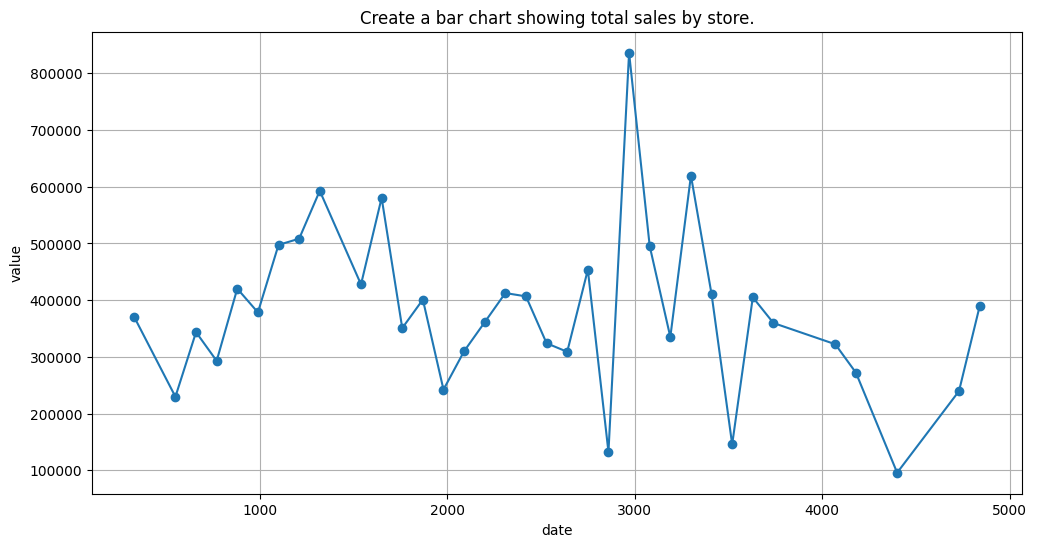

In [14]:
code_gen_df["label"] = code_gen_df["generated_code"].apply(code_is_runnable).map({True: "success", False: "fail"})
code_gen_df["score"] = code_gen_df["label"].map({"success": 1, "fail": 0})

In [15]:
code_gen_df.head()

,generated_code,label,score
context.span_id,,,
aae4e40a2b6bf943,import pandas as pd\nimport matplotlib.pyplot ...,success,1


In [16]:
px.Client().log_evaluations(
    SpanEvaluations(eval_name = "visualization code eval", dataframe = code_gen_df)
)

/usr/local/lib/python3.11/site-packages/phoenix/utilities/client.py:45: UserWarning: ⚠️⚠️ The Phoenix server (12.31.2) and client (7.0.0) versions are severely mismatched. Upgrade  either the client or server to ensure API compatibility ⚠️⚠️
  warnings.warn(
/usr/local/lib/python3.11/site-packages/phoenix/utilities/client.py:45: UserWarning: ⚠️⚠️ The Phoenix server (12.31.2) and client (7.0.0) versions are severely mismatched. Upgrade  either the client or server to ensure API compatibility ⚠️⚠️
  warnings.warn(


In [18]:
px.Client().log_evaluations(
    SpanEvaluations(eval_name = "visualization code eval", dataframe = code_gen_df)
)

/usr/local/lib/python3.11/site-packages/phoenix/utilities/client.py:45: UserWarning: ⚠️⚠️ The Phoenix server (12.31.2) and client (7.0.0) versions are severely mismatched. Upgrade  either the client or server to ensure API compatibility ⚠️⚠️
  warnings.warn(


## response quality eval

In [19]:
CLARITY_LLM_JUDGE_PROMPT = """
In this task, you will be presented with a query and an answer. Your objective is to evaluate the clarity 
of the answer in addressing the query. A clear response is one that is precise, coherent, and directly 
addresses the query without introducing unnecessary complexity or ambiguity. An unclear response is one 
that is vague, disorganized, or difficult to understand, even if it may be factually correct.

Your response should be a single word: either "clear" or "unclear," and it should not include any other 
text or characters. "clear" indicates that the answer is well-structured, easy to understand, and 
appropriately addresses the query. "unclear" indicates that some part of the response could be better 
structured or worded.
Please carefully consider the query and answer before determining your response.

After analyzing the query and the answer, you must write a detailed explanation of your reasoning to 
justify why you chose either "clear" or "unclear." Avoid stating the final label at the beginning of your 
explanation. Your reasoning should include specific points about how the answer does or does not meet the 
criteria for clarity.

[BEGIN DATA]
Query: {query}
Answer: {response}
[END DATA]
Please analyze the data carefully and provide an explanation followed by your response.

EXPLANATION: Provide your reasoning step by step, evaluating the clarity of the answer based on the query.
LABEL: "clear" or "unclear"
"""

In [20]:
query = SpanQuery().where(
    "span_kind == 'AGENT'"
).select(
    query = "input.value",
    response = "output.value"
)

response_df = px.Client().query_spans(
    query,
    project_name = PROJECT_NAME,
    timeout = None
)

In [21]:
response_df.head()

,query,response
context.span_id,,
6db77c46f94d3205,"[{""role"": ""user"", ""content"": ""What was the ave...",The average transaction value was approximatel...
3569bab9952b45a6,"[{""role"": ""user"", ""content"": ""What percentage ...",Approximately 62.56% of items were sold on pro...
d9ed7b49c12d6b80,"[{""role"": ""user"", ""content"": ""Create a bar cha...",Here is a bar chart showing total sales by sto...
24285f1d392f55e3,"[{""role"": ""user"", ""content"": ""Which store had ...",The store with the highest sales volume is Sto...
82f5a8bf4fa4f5b1,"[{""role"": ""user"", ""content"": ""What was the tot...",The total revenue across all stores was approx...


In [22]:
with suppress_tracing():
    response_eval = llm_classify(
        dataframe = response_df,
        template = CLARITY_LLM_JUDGE_PROMPT,
        rails = ["clear", "unclear"],
        model = OpenAIModel(model = "gpt-4o"),
        provide_explanation = True
    )
    
response_eval["score"] = response_eval.apply(lambda x: 1 if x["label"] == "clear" else 0, axis = 1)
response_eval.head()

/tmp/ipykernel_53/1550848106.py:2: DeprecationWarning: `dataframe` argument is deprecated; use `data` instead
  response_eval = llm_classify(


llm_classify |          | 0/6 (0.0%) | ⏳ 00:00<? | ?it/s

,label,explanation,exceptions,execution_status,execution_seconds,score
context.span_id,,,,,,
6db77c46f94d3205,clear,The query asks for the average transaction val...,[],COMPLETED,0.144809,1
3569bab9952b45a6,clear,The query asks for the percentage of items sol...,[],COMPLETED,0.233322,1
d9ed7b49c12d6b80,clear,The query asks for a bar chart showing total s...,[],COMPLETED,0.358361,1
24285f1d392f55e3,clear,The query asks for the store with the highest ...,[],COMPLETED,0.459661,1
82f5a8bf4fa4f5b1,clear,The query asks for the total revenue across al...,[],COMPLETED,0.531866,1


In [25]:
px.Client().log_evaluations(
    SpanEvaluations(eval_name = "response clarity", dataframe = response_eval),
)

/usr/local/lib/python3.11/site-packages/phoenix/utilities/client.py:45: UserWarning: ⚠️⚠️ The Phoenix server (12.31.2) and client (7.0.0) versions are severely mismatched. Upgrade  either the client or server to ensure API compatibility ⚠️⚠️
  warnings.warn(


## Evaluating sql code generation tool

In [26]:
SQL_EVAL_GEN_PROMPT = """
SQL Evaluation Prompt:
-----------------------
You are tasked with determining if the SQL generated appropiately answers a given instruction
taking into account its generated query and response.

Data:
-----
- [Instruction]: {question}
  This section contains the specific task or problem that the sql query is intended to solve.

- [Reference Query]: {query_gen}
  This is the sql query submitted for evaluation. Analyze it in the context of the provided
  instruction.

Evaluation:
-----------
Your response should be a single word: either "correct" or "incorrect".
You must assume that the db exists and that columns are appropiately named.
You must take into account the response as additional information to determine the correctness.

- "correct" indicates that the sql query correctly solves the instruction.
- "incorrect" indicates that the sql query correctly does not solve the instruction correctly.

Note: Your response should contain only the word "correct" or "incorrect" with no additional text
or characters.
"""

In [27]:
query = SpanQuery().where(
    "span_kind == 'LLM'"
).select(
    question = "input.value",
    query_gen = "llm.output_messages"
)

sql_df = px.Client().query_spans(
    query,
    project_name = PROJECT_NAME,
    timeout = None
)

sql_df.head()

,question,query_gen
context.span_id,,
191a014cf24a1408,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...",[{'message': {'tool_calls': [{'tool_call': {'i...
22a05dba08bd7c1e,"{""messages"": [{""role"": ""user"", ""content"": ""\nG...",[{'message': {'content': '```sql SELECT AVG(To...
10a7936300ebd246,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...",[{'message': {'content': 'The average transact...
8c8b8dd344938f1f,"{""messages"": [{""role"": ""user"", ""content"": ""Wha...",[{'message': {'tool_calls': [{'tool_call': {'i...
2184e67129c97c8d,"{""messages"": [{""role"": ""user"", ""content"": ""\nG...",[{'message': {'content': '```sql SELECT (...


we need to filter out the llm response that has sql query

In [32]:
sql_df = sql_df[sql_df["question"].str.contains("Generate an SQL query based on a prompt.", na = False)]
sql_df.head()

,question,query_gen
context.span_id,,
22a05dba08bd7c1e,"{""messages"": [{""role"": ""user"", ""content"": ""\nG...",[{'message': {'content': '```sql SELECT AVG(To...
2184e67129c97c8d,"{""messages"": [{""role"": ""user"", ""content"": ""\nG...",[{'message': {'content': '```sql SELECT (...
8803e9f915d99435,"{""messages"": [{""role"": ""user"", ""content"": ""\nG...",[{'message': {'content': '```sql SELECT Store_...
750e5f9b741c0fb1,"{""messages"": [{""role"": ""user"", ""content"": ""\nG...",[{'message': {'content': '```sql SELECT Store_...
e627c967aed11509,"{""messages"": [{""role"": ""user"", ""content"": ""\nG...",[{'message': {'content': '```sql SELECT SUM(To...


In [35]:
with suppress_tracing():
    sql_gen_eval = llm_classify(
        dataframe = sql_df,
        template = SQL_EVAL_GEN_PROMPT,
        rails = ["correct", "incorrect"],
        model = OpenAIModel(model = "gpt-4o"),
        provide_explanation = True
    )
    
sql_gen_eval["score"] = sql_gen_eval.apply(lambda x: 1 if x["label"] == "correct" else 0, axis = 1)
sql_gen_eval.head()

/tmp/ipykernel_53/3711676835.py:2: DeprecationWarning: `dataframe` argument is deprecated; use `data` instead
  sql_gen_eval = llm_classify(


llm_classify |          | 0/6 (0.0%) | ⏳ 00:00<? | ?it/s

,label,explanation,exceptions,execution_status,execution_seconds,score
context.span_id,,,,,,
22a05dba08bd7c1e,correct,The SQL query provided calculates the average ...,[],COMPLETED,0.173228,1
2184e67129c97c8d,correct,The SQL query calculates the percentage of ite...,[],COMPLETED,0.262519,1
8803e9f915d99435,correct,The SQL query provided correctly calculates th...,[],COMPLETED,0.367883,1
750e5f9b741c0fb1,correct,The SQL query provided calculates the total sa...,[],COMPLETED,0.459129,1
e627c967aed11509,correct,The SQL query provided in the reference query ...,[],COMPLETED,0.555076,1
